In [1]:

# SPPDEC Station Scaling Analysis


## Setup

In [2]:
import sys
from pathlib import Path

# Add the MultiAgentSimulator director￿y to path
sys.path.append(str(Path.cwd().parent.parent))

# Now you can import as a package
from analysis.notebook_utils import analyze_sweep, quick_sppdec_comparison
from analysis.sweep_analyzer import SweepAnalyzer
from analysis.slm_analyzer import SLMDecisionAnalyzer, load_slm_decisions
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set up plotting
plt.style.use('default')
sns.set_palette('tab10')
%matplotlib inline

In [3]:
## # Update this path to your station_scaling directory
sweep_dir = "../../experiments/station_scaling"

# Quick overview without loading all data
analyzer = SweepAnalyzer(sweep_dir)
config_summary = analyzer.get_config_summary()
print("Available configs:")
display(config_summary)

📊 SweepAnalyzer initialized for: station_scaling
Available configs:


,config_name,n_agents,n_parcels,n_experiments,is_loaded,n_strategies,completed_strategies,pending_strategies,experiment_status,seed,config_dir
0,A2_P4,2,4,80,False,80,80,0,completed,1769653743,../../experiments/station_scaling/A2_P4
1,A2_P6,2,6,80,False,80,80,0,completed,1769653743,../../experiments/station_scaling/A2_P6
2,A2_P8,2,8,80,False,80,80,0,completed,1769653743,../../experiments/station_scaling/A2_P8
3,A2_P12,2,12,80,False,80,80,0,completed,1769653743,../../experiments/station_scaling/A2_P12
4,A2_P14,2,14,80,False,80,80,0,completed,1769653743,../../experiments/station_scaling/A2_P14
...,...,...,...,...,...,...,...,...,...,...,...
59,A20_P20,20,20,80,False,80,80,0,completed,1769792310,../../experiments/station_scaling/A20_P20
60,A20_P24,20,24,80,False,80,80,0,completed,1769915714,../../experiments/station_scaling/A20_P24
61,A20_P26,20,26,80,False,80,79,0,completed,1769953968,../../experiments/station_scaling/A20_P26
62,A20_P30,20,30,80,False,80,78,0,completed,1769964134,../../experiments/station_scaling/A20_P30


In [4]:
# Load all experiments with progress tracking (reliable, no hanging)  
notebook_analyzer = analyze_sweep(sweep_dir, show_progress=True)
df = notebook_analyzer.sweep.dataframe
print(f"Loaded {len(df)} strategy runs across {len(df['config_name'].unique())} configurations")
print(f"Strategy families: {df['strategy_family'].nunique()}")
print(f"Scale range: {df['n_agents'].min()}-{df['n_agents'].max()} agents, {df['n_parcels'].min()}-{df['n_parcels'].max()} parcels")

📊 SweepAnalyzer initialized for: station_scaling
📊 Loading experiment data...
📁 Loading 64 configurations...
⏳ Loading configurations...
🔄 Loading 64 configs: ['A2_P4', 'A2_P6', 'A2_P8', 'A2_P12', 'A2_P14', 'A2_P20', 'A2_P24', 'A2_P26', 'A2_P30', 'A2_P36', 'A3_P36', 'A4_P4', 'A4_P10', 'A4_P12', 'A4_P24', 'A4_P36', 'A6_P4', 'A6_P8', 'A6_P12', 'A6_P14', 'A6_P20', 'A6_P24', 'A6_P26', 'A6_P30', 'A6_P36', 'A8_P4', 'A8_P12', 'A8_P18', 'A8_P24', 'A8_P36', 'A10_P4', 'A10_P8', 'A10_P12', 'A10_P14', 'A10_P20', 'A10_P22', 'A10_P24', 'A10_P26', 'A10_P30', 'A10_P36', 'A12_P4', 'A12_P12', 'A12_P24', 'A12_P26', 'A12_P36', 'A15_P4', 'A15_P8', 'A15_P12', 'A15_P14', 'A15_P20', 'A15_P24', 'A15_P26', 'A15_P30', 'A15_P36', 'A18_P36', 'A20_P4', 'A20_P8', 'A20_P12', 'A20_P14', 'A20_P20', 'A20_P24', 'A20_P26', 'A20_P30', 'A20_P36']
✓ Loaded A2_P4: 80 strategies, 2A×4P, seed=1769653743
✓ Loaded A2_P6: 80 strategies, 2A×6P, seed=1769653743
✓ Loaded A2_P8: 80 strategies, 2A×8P, seed=1769653743
✓ Loaded A2_P12: 8

In [5]:
# SLM decision-level analysis — parallel to notebook_analyzer
slm = load_slm_decisions(sweep_dir)
slm_df = slm.dataframe
print(f"SLM decisions: {len(slm_df)} across {slm_df['strategy_name'].nunique()} strategy(ies)")

📊 SLMDecisionAnalyzer initialized for: station_scaling
🔄 Found 5279 fleet.json file(s)
✅ Loaded 5279 fleet file(s) — 14605 total SLM decisions
📊 Built SLM DataFrame: 14605 decisions | 6 config(s) | 45 strategy(ies) | 18 unique agent id(s)
SLM decisions: 14605 across 45 strategy(ies)


In [6]:
slm.policy_distribution()

,config_name,strategy_name,policy,count,pct
0,A12_P36,sppdec_baseline_only_instance_1,greedy,28,54.9
1,A12_P36,sppdec_baseline_only_instance_1,hungarian,23,45.1
2,A12_P36,sppdec_baseline_only_instance_2,greedy,28,50.9
3,A12_P36,sppdec_baseline_only_instance_2,hungarian,27,49.1
4,A12_P36,sppdec_baseline_only_instance_3,greedy,52,71.2
...,...,...,...,...,...
511,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_3,hungarian,2,4.2
512,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_4,greedy,39,90.7
513,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_4,hungarian,4,9.3
514,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_5,greedy,57,96.6


In [7]:
slm.per_agent_summary()

,config_name,strategy_name,agent_id,policy,n_decisions,mean_confidence,mean_belief,mean_energy_error,mean_competition,mean_cost_delta
0,A12_P36,sppdec_baseline_only_instance_1,agent_0,greedy,2,0.5273,0.5000,0.8573,0.3492,0.5652
1,A12_P36,sppdec_baseline_only_instance_1,agent_0,hungarian,1,0.4038,0.5000,1.3892,0.8462,1.6025
2,A12_P36,sppdec_baseline_only_instance_1,agent_1,greedy,2,0.7264,0.5000,0.5827,0.3492,0.8034
3,A12_P36,sppdec_baseline_only_instance_1,agent_1,hungarian,2,0.4711,0.5000,1.1542,0.8735,0.8385
4,A12_P36,sppdec_baseline_only_instance_1,agent_10,greedy,2,0.6767,0.5000,1.0898,0.3302,0.1512
...,...,...,...,...,...,...,...,...,...,...
4526,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_5,agent_5,greedy,3,1.0000,0.5000,0.1330,0.3796,0.0000
4527,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_5,agent_6,greedy,4,1.0000,0.5000,0.0974,0.4427,0.0000
4528,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_5,agent_7,greedy,5,0.8700,0.6000,0.1009,0.4386,0.1955
4529,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_5,agent_8,greedy,7,0.8857,0.6798,0.0888,0.5047,0.3913


In [8]:
slm.switching_rate()

,config_name,strategy_name,n_decisions,n_switched,switch_rate
0,A12_P36,sppdec_baseline_only_instance_1,51,23,0.4510
1,A12_P36,sppdec_baseline_only_instance_2,55,27,0.4909
2,A12_P36,sppdec_baseline_only_instance_3,73,21,0.2877
3,A12_P36,sppdec_baseline_only_instance_4,52,18,0.3462
4,A12_P36,sppdec_baseline_only_instance_5,64,26,0.4062
...,...,...,...,...,...
265,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_1,52,6,0.1154
266,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_2,55,3,0.0545
267,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_3,48,2,0.0417
268,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_4,43,4,0.0930


In [9]:
slm.divergence_events(threshold=0.01)

,config_name,n_agents,n_parcels,run_id,strategy_name,agent_id,step,sim_time,world_time,policy,...,competition_ratio,belief_trend,error_trend,competition_trend,cost_greedy,cost_hungarian,cost_chosen,cost_delta,switched,is_fallback
0,A12_P36,12.0,36.0,experiment_dfe070be,sppdec_personality_mix_efficiency_overdrive_in...,agent_3,5,0.083333,1.776389e+09,greedy,...,0.379310,STABLE,RISING,RISING,2.199015,2.209114,2.199015,0.010099,False,False
1,A12_P36,12.0,36.0,experiment_dfe070be,sppdec_personality_mix_balanced_quartet_instan...,agent_4,8,0.133333,1.776389e+09,greedy,...,0.458333,STABLE,RISING,RISING,2.988427,2.998671,2.988427,0.010243,False,False
2,A18_P36,18.0,36.0,experiment_965e7a19,sppdec_personality_mix_controlled_chaos_instan...,agent_0,5,0.083333,1.776517e+09,hungarian,...,0.772727,STABLE,RISING,RISING,2.684069,2.694565,2.694565,0.010496,True,False
3,_A12_P36_belief_tracking_disabled,NaN,NaN,experiment_dfe070be,sppdec_personality_mix_balanced_quartet_instan...,agent_5,3,0.050000,1.774863e+09,greedy,...,0.366667,STABLE,STABLE,RISING,2.002214,2.012772,2.002214,0.010558,False,False
4,_A12_P36_belief_tracking_disabled,NaN,NaN,experiment_dfe070be,sppdec_personality_mix_balanced_quartet_instan...,agent_1,3,0.050000,1.774863e+09,greedy,...,0.366667,STABLE,STABLE,RISING,2.002214,2.012772,2.002214,0.010558,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6248,A3_P36,3.0,36.0,experiment_73ad2ffb,sppdec_personality_mix_no_reckless_instance_3,agent_0,2466,41.100000,1.776480e+09,greedy,...,0.666667,STABLE,RISING,RISING,0.754544,6.828334,0.754544,6.073790,False,False
6249,A3_P36,3.0,36.0,experiment_73ad2ffb,sppdec_personality_mix_controlled_chaos_instan...,agent_2,2243,37.383333,1.776478e+09,greedy,...,0.500000,FALLING,RISING,RISING,2.291556,9.245279,2.291556,6.953723,False,False
6250,A6_P36,6.0,36.0,experiment_76e01b24,sppdec_fairness_only_instance_1,agent_3,850,14.166667,1.776488e+09,greedy,...,1.250000,FALLING,RISING,RISING,4.137276,11.772244,4.137276,7.634968,False,False
6251,A6_P36,6.0,36.0,experiment_76e01b24,sppdec_fairness_only_instance_1,agent_1,847,14.116667,1.776488e+09,greedy,...,1.250000,STABLE,RISING,RISING,4.137276,11.772244,4.137276,7.634968,False,False


In [10]:
slm.context_profile()

,config_name,strategy_name,policy,belief_infeasibility,energy_error,competition_ratio,confidence
0,A12_P36,sppdec_baseline_only_instance_1,greedy,0.5000,1.1085,0.3459,0.6600
1,A12_P36,sppdec_baseline_only_instance_1,hungarian,0.6087,1.8395,0.9668,0.4107
2,A12_P36,sppdec_baseline_only_instance_2,greedy,0.5179,1.1499,0.3928,0.6841
3,A12_P36,sppdec_baseline_only_instance_2,hungarian,0.6587,1.8847,1.5092,0.3610
4,A12_P36,sppdec_baseline_only_instance_3,greedy,0.6472,1.6803,0.5823,0.6729
...,...,...,...,...,...,...,...
511,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_3,hungarian,0.5000,1.5681,0.6493,0.5000
512,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_4,greedy,0.5256,0.4932,0.5253,0.9179
513,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_4,hungarian,0.5000,0.7677,0.5975,0.5000
514,_A12_P36_full_observality,sppdec_personality_mix_no_reckless_instance_5,greedy,0.6066,0.3411,0.4793,0.9044


In [11]:
run_df   = notebook_analyzer.sweep.dataframe   # one row per strategy run
slm_agg  = slm.switching_rate()                # one row per (config, strategy)

merged = run_df.merge(
    slm_agg[["config_name", "strategy_name", "switch_rate"]],
    on=["config_name", "strategy_name"],
    how="left"
)

In [12]:
# Quick overview of the sweep
notebook_analyzer.quick_overview()

🔍 SWEEP OVERVIEW
Sweep name: station_scaling
Available configs: 64
Loaded configs: 63

Config Details:
config_name  n_agents  n_parcels  is_loaded  n_strategies  completed_strategies
      A2_P4         2          4       True            80                    80
      A2_P6         2          6       True            80                    80
      A2_P8         2          8       True            80                    80
     A2_P12         2         12       True            80                    80
     A2_P14         2         14       True            80                    80
     A2_P20         2         20       True            80                    80
     A2_P24         2         24       True            80                    80
     A2_P26         2         26       True            80                    80
     A2_P30         2         30       True            80                    80
     A2_P36         2         36       True            80                    80
     A3_P36      

In [13]:
# Strategy performance overview
strategy_summary = notebook_analyzer.strategy_overview()
print("Strategy Performance Summary:")
display(strategy_summary)

Strategy Performance Summary:


,n_configs,n_runs,mean_makespan,std_makespan,mean_energy,std_energy,total_failures
strategy_family,,,,,,,
cbba_single_task_cbba_single,63,63,928.72,692.74,142.41,74.85,44409
centralized_cc_hungarian_hungarian,63,63,935.86,703.02,111.72,61.03,46558
centralized_cc_auction,63,63,937.44,701.90,111.19,60.88,44333
sppdec_personality_mix_3_brains_1_wildcard,63,63,939.10,522.70,172.52,69.49,312153
sppdec_personality_mix_efficiency_overdrive,63,63,946.00,522.92,172.03,70.25,319009
sppdec_personality_mix_no_reckless,63,63,946.12,505.79,173.70,70.07,318928
sppdec_personality_mix_controlled_chaos,63,63,950.83,511.96,174.13,71.67,316253
sppdec_personality_mix_balanced_quartet,63,63,956.47,497.29,173.42,71.23,318621
sppdec_control,63,63,959.20,501.96,175.93,73.03,315400


📈 SPPDEC Phase Comparison: mission_makespan_steps

Mean performance by phase and config:
config_name    A10_P12  A10_P14  A10_P20  A10_P22  A10_P24  A10_P26  A10_P30  A10_P36  A10_P4  A10_P8  A12_P12  A12_P24  A12_P26  A12_P4  A15_P12  A15_P14  A15_P20  A15_P24  A15_P26  A15_P30  A15_P36  A15_P4  A15_P8  A18_P36  A20_P12  A20_P14  A20_P20  A20_P24  A20_P26  A20_P30  A20_P36  A20_P4  A20_P8  A2_P12  A2_P14  A2_P20  A2_P24  A2_P26  A2_P30  A2_P36  A2_P4  A2_P6   A2_P8  A3_P36  A4_P10  A4_P12  A4_P24  A4_P36  A4_P4  A6_P12  A6_P14  A6_P20  A6_P24  A6_P26  A6_P30  A6_P36  A6_P4  A6_P8  A8_P12  A8_P18  A8_P24  A8_P36  A8_P4
sppdec_phase                                                                                                                                                                                                                                                                                                                                                                         

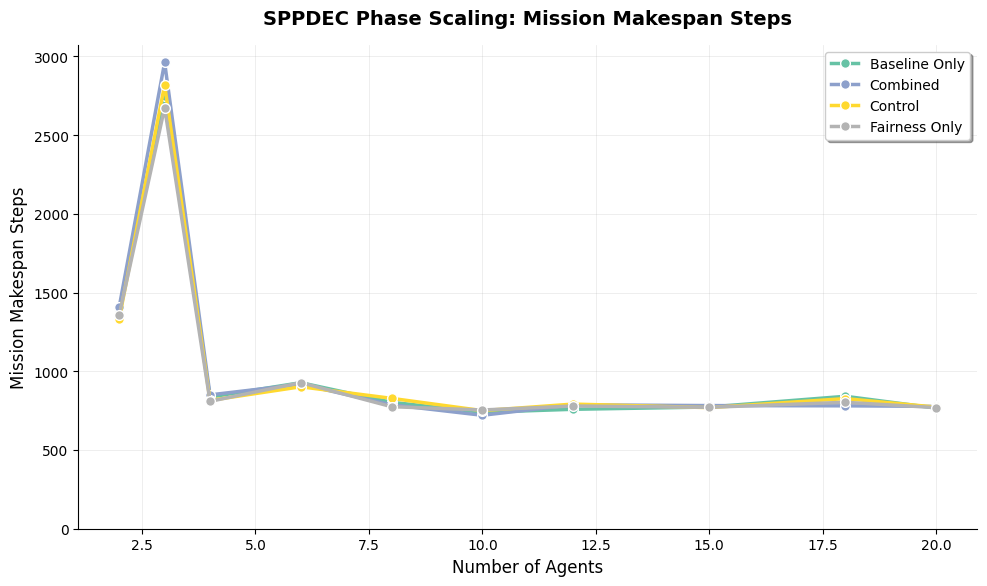

In [14]:
# Compare SPPDEC phases on mission makespan
notebook_analyzer.compare_sppdec_phases('mission_makespan_steps')

In [15]:
# Get SPPDEC data for detailed analysis
sppdec_df = notebook_analyzer.sweep.get_sppdec_phases()
if not sppdec_df.empty:
    print("SPPDEC Phase Distribution:")
    display(sppdec_df.groupby(['sppdec_phase', 'config_name']).size().unstack(fill_value=0))
    
    # Detailed performance metrics
    metrics_summary = sppdec_df.groupby('sppdec_phase')[[
        'mission_makespan_steps', 'total_energy_consumed', 'unsafe_failures', 'messages_sent'
    ]].agg(['mean', 'std']).round(2)
    
    print("\nDetailed SPPDEC Metrics:")
    display(metrics_summary)

SPPDEC Phase Distribution:


config_name,A10_P12,A10_P14,A10_P20,A10_P22,A10_P24,A10_P26,A10_P30,A10_P36,A10_P4,A10_P8,...,A6_P26,A6_P30,A6_P36,A6_P4,A6_P8,A8_P12,A8_P18,A8_P24,A8_P36,A8_P4
sppdec_phase,,,,,,,,,,,,,,,,,,,,,
Baseline Only,5,5,5,5,5,5,5,5,5,5,...,5,5,6,5,5,5,5,5,5,5
Combined,5,5,5,5,5,5,5,5,5,5,...,5,5,6,5,5,5,5,5,5,5
Control,5,5,5,5,5,5,4,5,5,5,...,5,5,6,5,5,5,5,5,5,5
Fairness Only,5,5,5,5,5,5,5,5,5,5,...,5,5,6,5,5,5,5,5,5,5



Detailed SPPDEC Metrics:


mission_makespan_steps         total_energy_consumed         \
                                mean     std                  mean    std   
sppdec_phase                                                                
Baseline Only                1020.84  613.80                179.09  73.51   
Combined                     1027.63  636.55                180.31  74.63   
Control                      1027.88  618.77                180.58  74.83   
Fairness Only                1026.14  596.79                179.54  74.86   

              unsafe_failures         messages_sent       
                         mean     std          mean  std  
sppdec_phase                                              
Baseline Only          962.13  617.99           0.0  0.0  
Combined               963.33  630.56           0.0  0.0  
Control                944.31  614.97           0.0  0.0  
Fairness Only          966.05  630.21           0.0  0.0

📊 Baseline Strategy Comparison
📊 Selected top 5 strategies (of 7 total)
  1. CBBA Single Task: 995.6
  2. Centralized Hungarian: 1004.0
  3. Centralized Auction: 1004.7
  4. Centralized Greedy: 1068.6
  5. Decentralized Auction: 1193.5


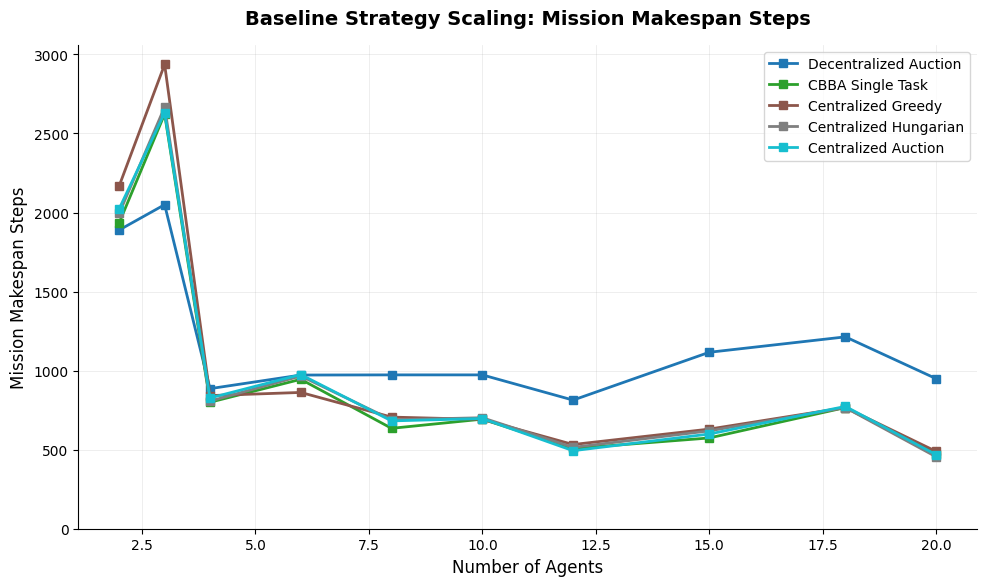

In [16]:
# Clean baseline comparison - baselines only
notebook_analyzer.compare_baselines_only('mission_makespan_steps')

🎯 SPPDEC vs Best Baseline
Best baseline: CBBA Single Task


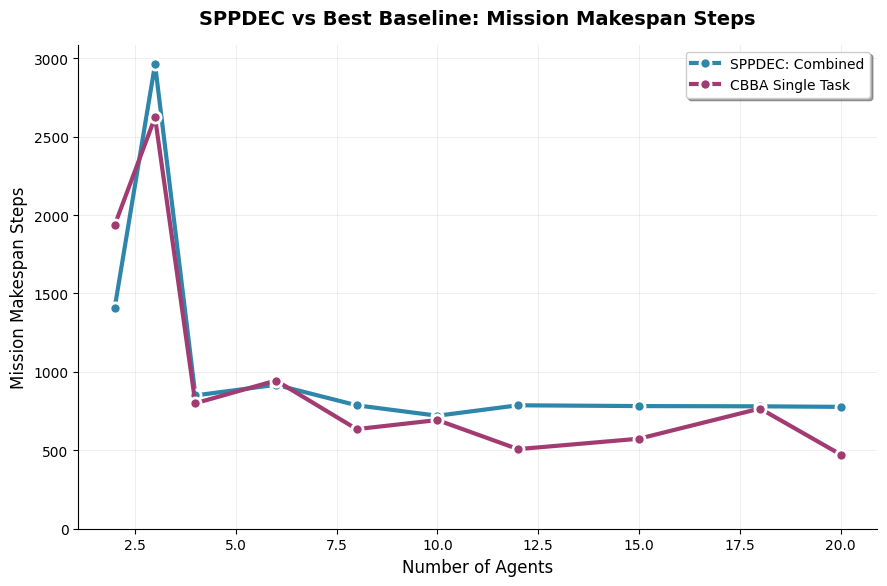

In [17]:
# Direct head-to-head comparison
notebook_analyzer.sppdec_vs_best_baseline('mission_makespan_steps')

📊 Selected top 5 strategies (of 7 total)
  1. CBBA Single Task: 995.6
  2. Centralized Hungarian: 1004.0
  3. Centralized Auction: 1004.7
  4. Centralized Greedy: 1068.6
  5. Decentralized Auction: 1193.5


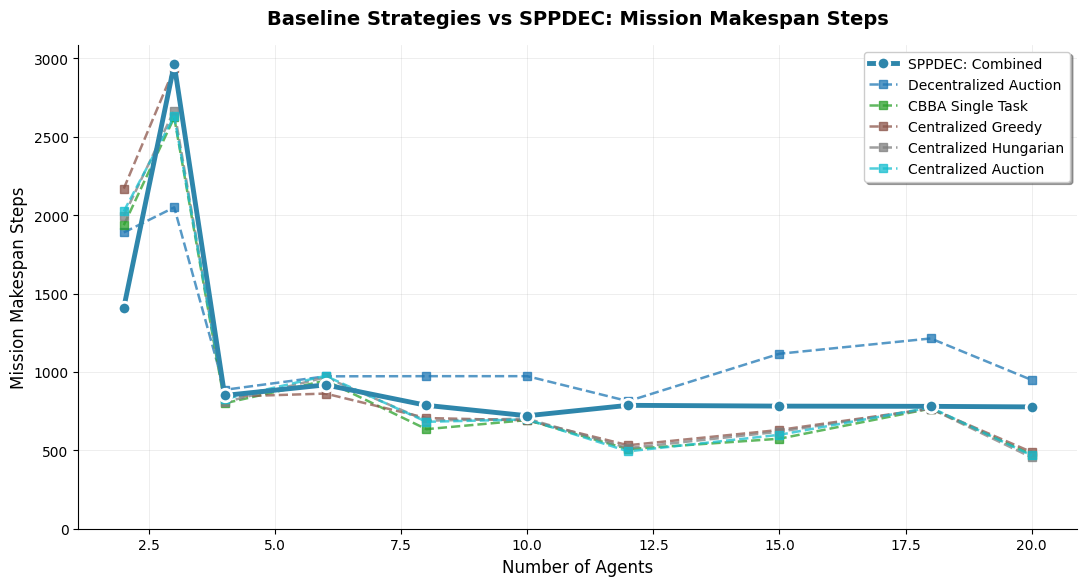


📊 Summary (mission_makespan_steps, median across all scales):
──────────────────────────────────────────────────
  SPPDEC: Combined                         816.0  ◄ SPPDEC
  Decentralized Auction                    1087.0
  CBBA Single Task                         708.0
  Centralized Greedy                       717.0
  Centralized Hungarian                    717.0
  Centralized Auction                      707.0


In [18]:
notebook_analyzer.compare_baselines_and_sppdec_combined('mission_makespan_steps')

🔸 Multi-Metric Polygon Performance Comparison
📊 Loaded 7 baseline strategies
📊 Loaded 4 SPPDEC strategies
🎭 Showing top 5 personalities (of 6 total)
📊 Loaded 5 personality strategies

🎯 Total strategies for comparison: 16

🎯 Baseline vs SPPDEC Comparison (14 strategies)


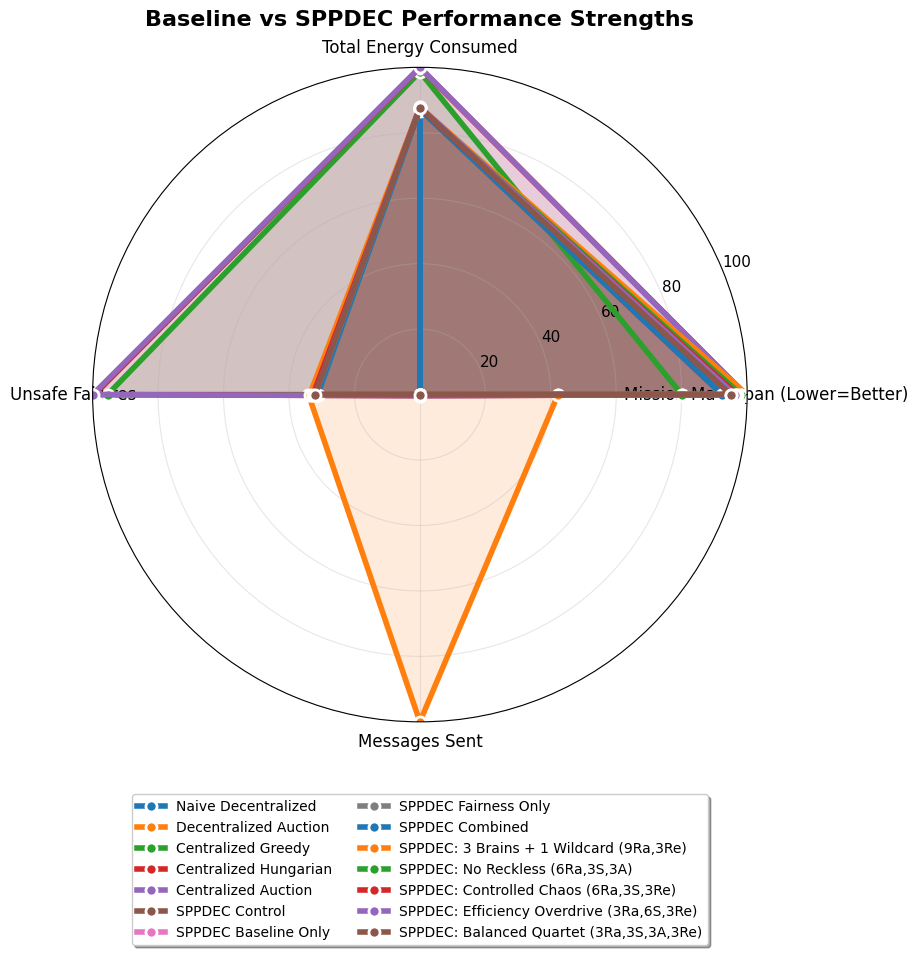


📊 Performance Interpretation (100 = best possible):
   • Larger polygon area = better overall performance
   • Makespan, Energy, Failures: lower actual values = higher scores
   • Messages, Completion Rate: higher actual values = higher scores

🎭 Personality Performance Comparison (5 personalities)


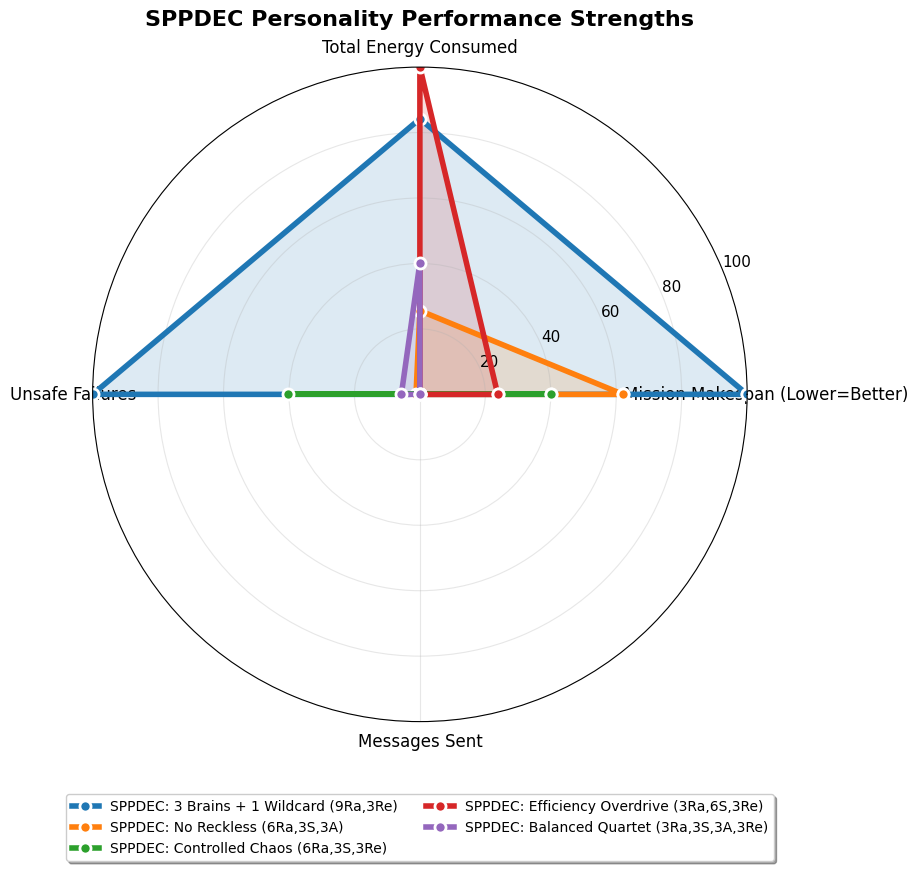


📊 Performance Interpretation (100 = best possible):
   • Larger polygon area = better overall performance
   • Makespan, Energy, Failures: lower actual values = higher scores
   • Messages, Completion Rate: higher actual values = higher scores

🏆 Champion Comparison (3 top performers)


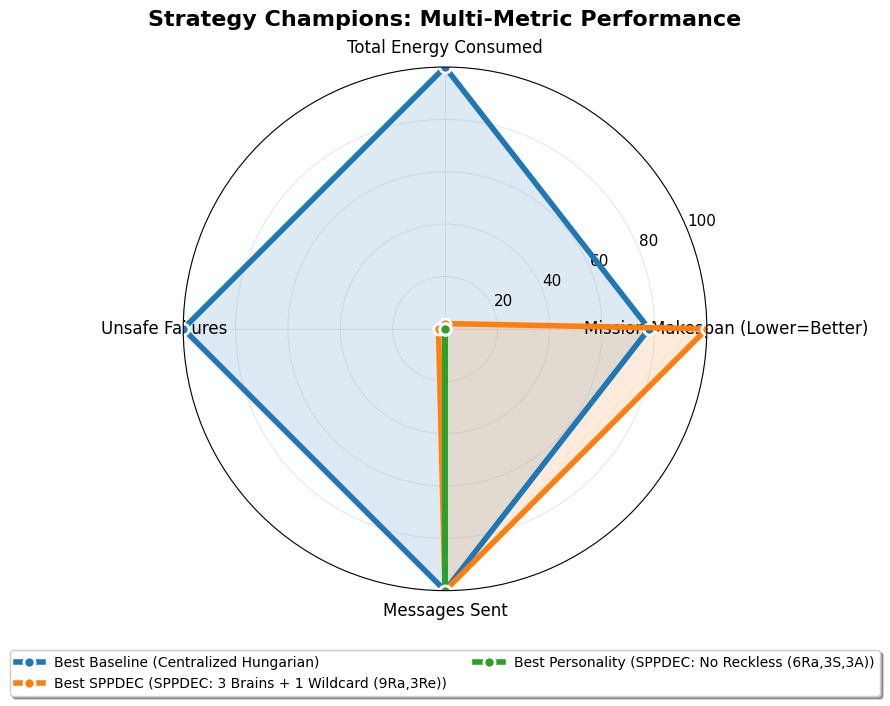


📊 Performance Interpretation (100 = best possible):
   • Larger polygon area = better overall performance
   • Makespan, Energy, Failures: lower actual values = higher scores
   • Messages, Completion Rate: higher actual values = higher scores


In [19]:
# Complete multi-metric polygon comparison
notebook_analyzer.comprehensive_polygon_comparison()

## Strategy Ranking Analysis

How consistently does each strategy perform across different scales?

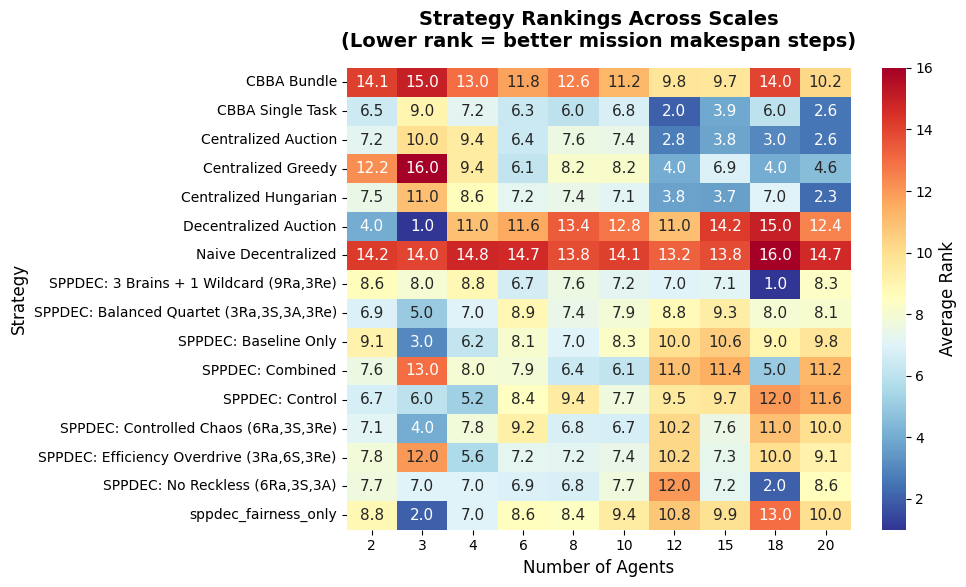

In [20]:
# Much cleaner ranking visualization
notebook_analyzer.ranking_heatmap('mission_makespan_steps')

## Pareto Analysis

Speed vs energy tradeoffs:

⚡ Energy Efficiency Scaling Analysis


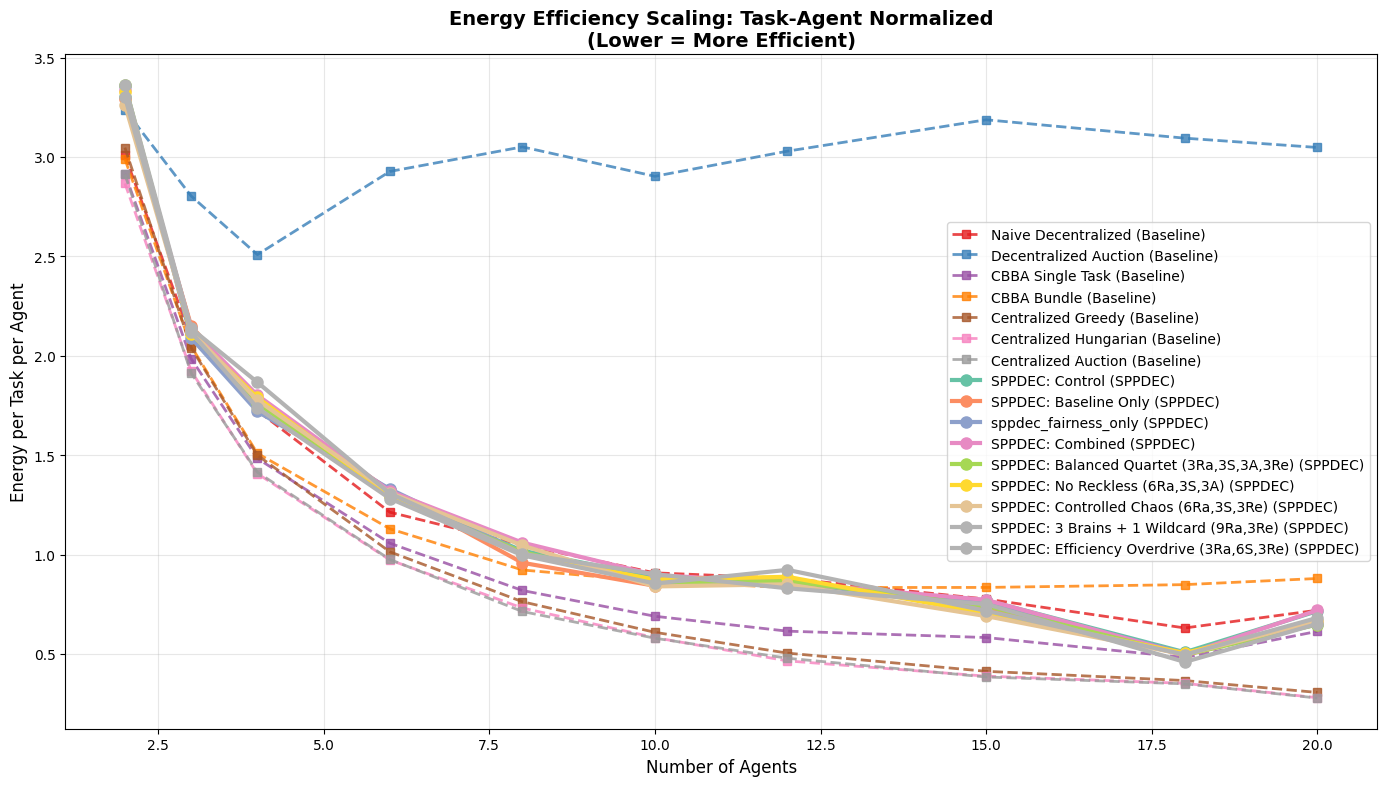


📊 Efficiency Summary (Task-Agent Normalized):
                                              mean    std
strategy_family                                          
centralized_cc_auction                       1.049  0.891
centralized_cc_hungarian_hungarian           1.053  0.895
centralized_cc_greedy_greedy                 1.110  0.932
cbba_single_task_cbba_single                 1.202  0.825
cbba_full_cbba_bundle                        1.329  0.769
naive_decentralized_reactive                 1.541  0.913
sppdec_personality_mix_efficiency_overdrive  1.567  1.012
sppdec_personality_mix_balanced_quartet      1.578  1.016
sppdec_personality_mix_3_brains_1_wildcard   1.580  1.022
sppdec_personality_mix_controlled_chaos      1.580  1.009
sppdec_baseline_only                         1.582  1.007
sppdec_combined                              1.583  1.005
sppdec_personality_mix_no_reckless           1.584  1.023
sppdec_fairness_only                         1.585  1.028
sppdec_control           

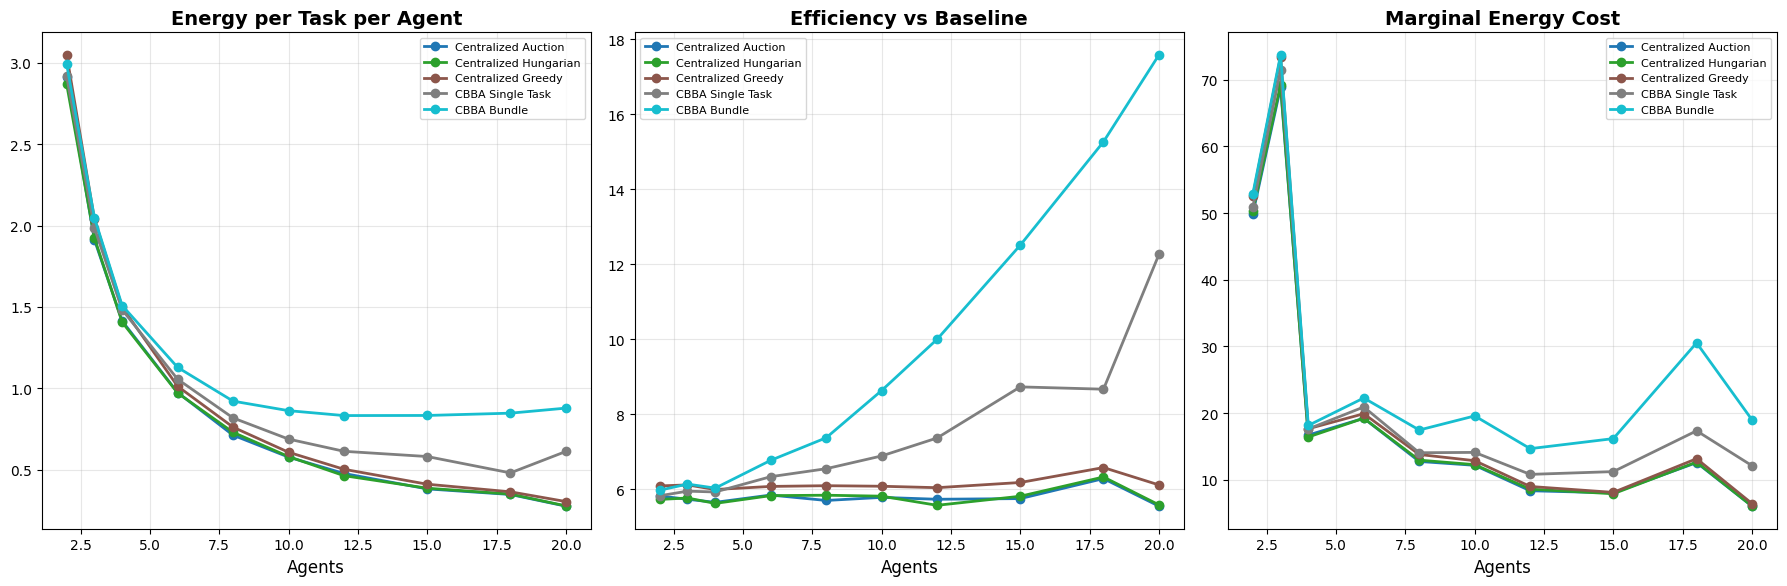

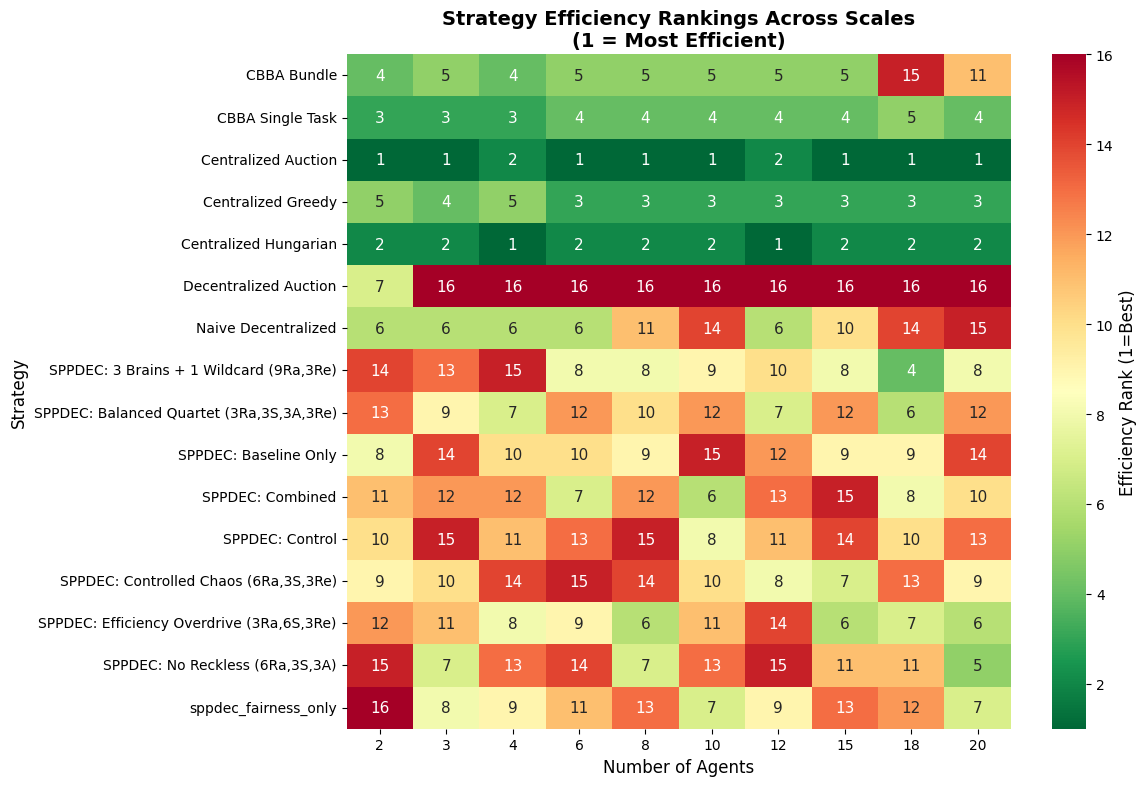

In [21]:
notebook_analyzer.plot_energy_efficiency_scaling("tasks_per_agent")
notebook_analyzer.plot_energy_efficiency_comparison()
notebook_analyzer.plot_efficiency_ranking_by_scale()

In [22]:
# Debug the entire personality data pipeline
notebook_analyzer.personality_distribution_radar_debug()

# Or inspect the raw JSON directly
notebook_analyzer.inspect_personality_data_directly('A12_P36')  # or whatever config name you have

🔍 DEBUG: Personality Distribution Analysis
📊 Total DataFrame rows: 5351
📊 Available columns: ['personality_distribution', 'personality_map']

🔍 Checking personality_distribution column:
📊 Non-null personality entries: 5351
📊 First few personality distributions:
   1. {'rational': 1, 'selfish': 1} (type: <class 'dict'>)
   2. {'rational': 1, 'selfish': 1} (type: <class 'dict'>)
   3. {'rational': 1, 'selfish': 1} (type: <class 'dict'>)

🔍 After get_personality_variants() filtering:
📊 Personality DataFrame rows: 2004

🔍 Checking distributions in filtered data:
📊 Strategy 'sppdec_fairness_only': 334 non-null distributions
   └─ First distribution: {'rational': 1, 'selfish': 1} (type: <class 'dict'>)
📊 Strategy 'sppdec_personality_mix_3_brains_1_wildcard': 334 non-null distributions
   └─ First distribution: {'rational': 2} (type: <class 'dict'>)
📊 Strategy 'sppdec_personality_mix_balanced_quartet': 334 non-null distributions
   └─ First distribution: {'rational': 1, 'selfish': 1} (type: <

In [23]:
# Rationale:  A12_P36: Optimal for personality analysis - 12 agents (3 per personality type in balanced teams)
# with 36 parcels (3 tasks/agent) creates meaningful coordination pressure where personality
# composition effects become visible. Large enough for statistical significance, complex enough
# to show SPPDEC variant differences, yet manageable for clear analysis.

notebook_analyzer.personality_distribution_radar("A12_P36")

⚠️  No personality data found for config: A12_P36
💡  Available configs: ['A2_P4', 'A2_P6', 'A2_P8', 'A2_P12', 'A2_P14', 'A2_P20', 'A2_P24', 'A2_P26', 'A2_P30', 'A2_P36', 'A3_P36', 'A4_P4', 'A4_P10', 'A4_P12', 'A4_P24', 'A4_P36', 'A6_P4', 'A6_P8', 'A6_P12', 'A6_P14', 'A6_P20', 'A6_P24', 'A6_P26', 'A6_P30', 'A6_P36', 'A8_P4', 'A8_P12', 'A8_P18', 'A8_P24', 'A8_P36', 'A10_P4', 'A10_P8', 'A10_P12', 'A10_P14', 'A10_P20', 'A10_P22', 'A10_P24', 'A10_P26', 'A10_P30', 'A10_P36', 'A12_P4', 'A12_P12', 'A12_P24', 'A12_P26', 'A15_P4', 'A15_P8', 'A15_P12', 'A15_P14', 'A15_P20', 'A15_P24', 'A15_P26', 'A15_P30', 'A15_P36', 'A18_P36', 'A20_P4', 'A20_P8', 'A20_P12', 'A20_P14', 'A20_P20', 'A20_P24', 'A20_P26', 'A20_P30', 'A20_P36']


🎭 SPPDEC Personality Analysis

🧠 Personality Mix Compositions:
----------------------------------------
  • sppdec_fairness_only:
    └─ Custom personality configuration
  • SPPDEC: 3 Brains + 1 Wildcard (9Ra,3Re):
    └─ 3 analytical agents + 1 unpredictable agent
  • SPPDEC: Balanced Quartet (3Ra,3S,3A,3Re):
    └─ Equal distribution of all personality types
  • SPPDEC: Controlled Chaos (6Ra,3S,3Re):
    └─ Structured agents with controlled randomness
  • SPPDEC: Efficiency Overdrive (3Ra,6S,3Re):
    └─ High efficiency agents, minimal exploration
  • SPPDEC: No Reckless (6Ra,3S,3A):
    └─ Conservative agents, no high-risk behaviors

💡 Understanding: Each mix represents different agent behavior combinations
   affecting coordination strategies, risk tolerance, and decision speed.

📊 Performance Summary:
                                            mission_makespan_steps               total_energy_consumed        unsafe_failures config_name
                                            

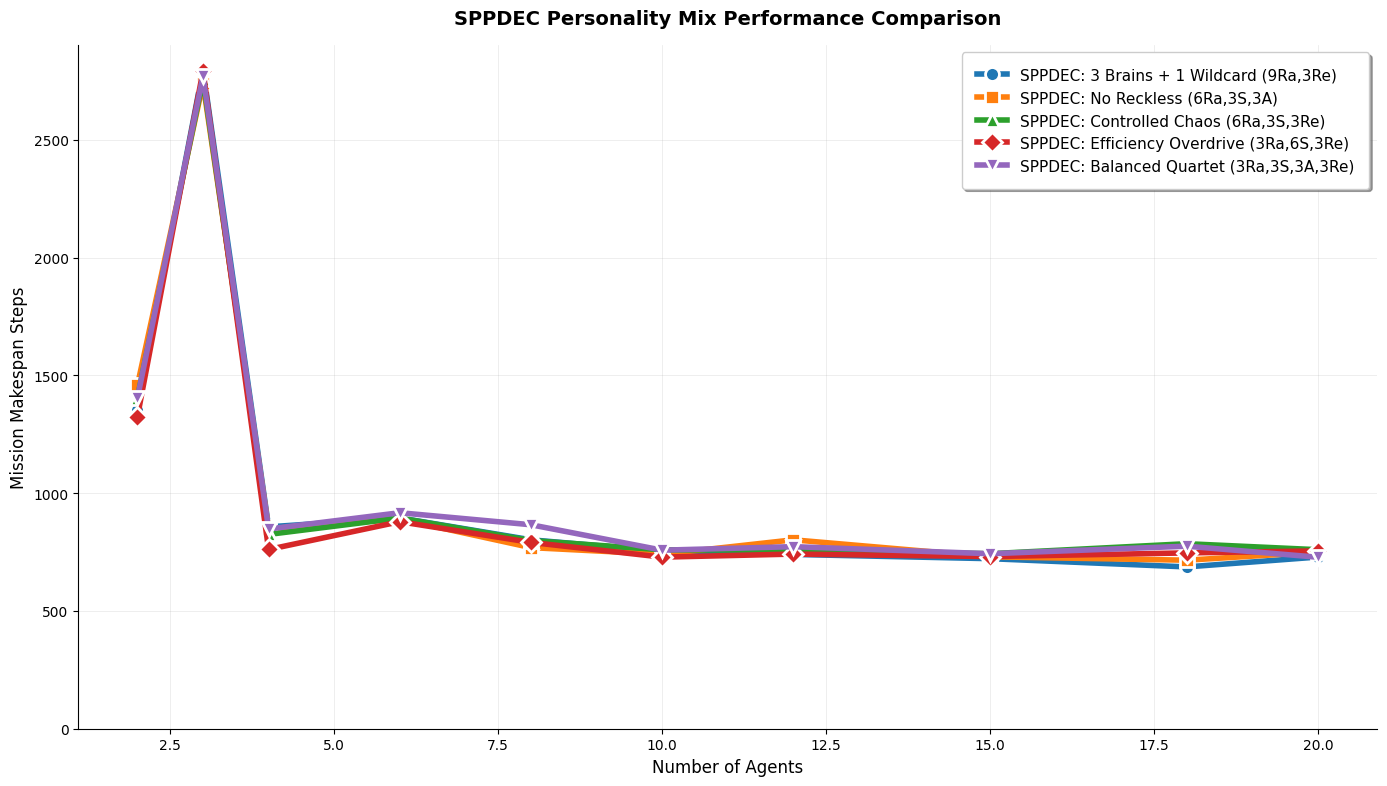


📋 Personality Display Names Reference:
  • SPPDEC: 3 Brains + 1 Wildcard (9Ra,3Re) = sppdec_personality_mix_3_brains_1_wildcard
  • SPPDEC: No Reckless (6Ra,3S,3A) = sppdec_personality_mix_no_reckless
  • SPPDEC: Controlled Chaos (6Ra,3S,3Re) = sppdec_personality_mix_controlled_chaos
  • SPPDEC: Efficiency Overdrive (3Ra,6S,3Re) = sppdec_personality_mix_efficiency_overdrive
  • SPPDEC: Balanced Quartet (3Ra,3S,3A,3Re) = sppdec_personality_mix_balanced_quartet


In [24]:
try:
    # Performance comparison (your improved line graph)
    notebook_analyzer.personality_analysis('mission_makespan_steps')   
except Exception as e:
    print("No personality data available:", e)

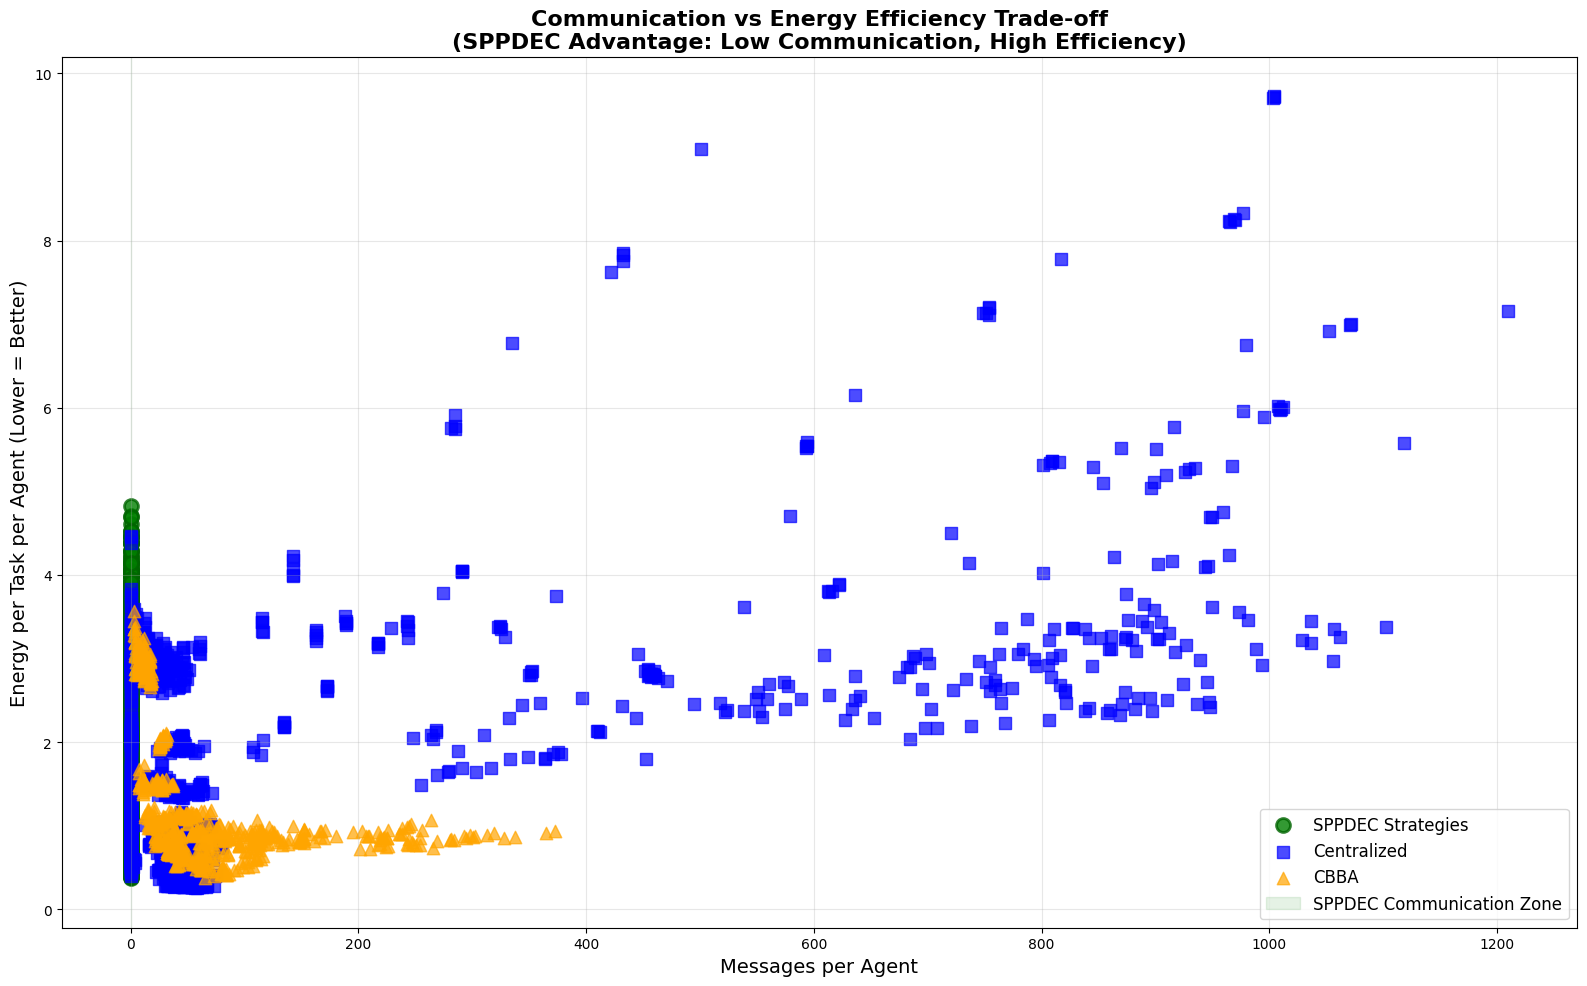


📡 Communication vs Efficiency Summary:
                                            messages_per_agent          energy_efficiency        messages_sent
                                                          mean      std              mean    std          mean
strategy_family                                                                                               
naive_decentralized_reactive                             0.000    0.000             1.541  0.913         0.000
sppdec_baseline_only                                     0.000    0.000             1.582  1.007         0.000
sppdec_personality_mix_controlled_chaos                  0.000    0.000             1.580  1.009         0.000
sppdec_personality_mix_balanced_quartet                  0.000    0.000             1.578  1.016         0.000
sppdec_personality_mix_3_brains_1_wildcard               0.000    0.000             1.580  1.022         0.000
sppdec_fairness_only                                     0.000    0.000 

In [25]:
notebook_analyzer.plot_communication_vs_efficiency()

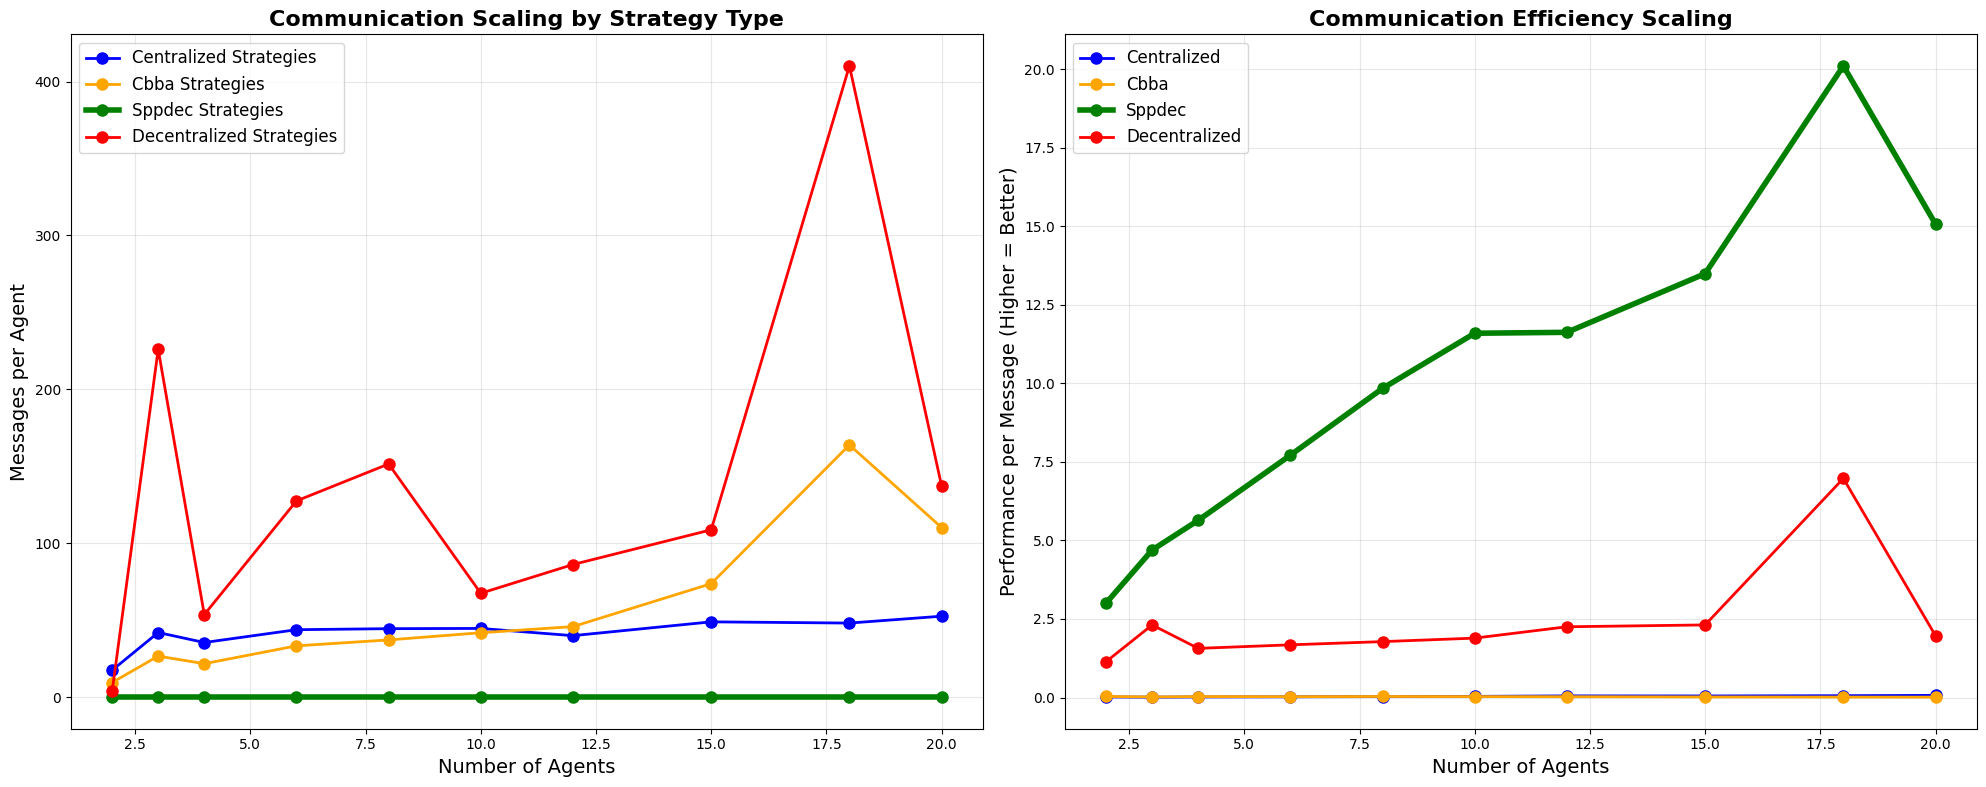

In [26]:
notebook_analyzer.plot_communication_scaling()

/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/notebook_utils.py:2251: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = df.groupby(['efficiency_category', 'strategy_type'])['comm_efficiency'].agg(
/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/notebook_utils.py:2344: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  strategy_summary = df.groupby(['strategy_type', 'efficiency_category']).agg({
/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/notebook_utils.py:2385: FutureWarning: The default of observed=False is deprecated and will be changed to True

Summary data for debugging:
  efficiency_category strategy_type         mean  count
0     High Efficiency          CBBA     0.028003    204
1     High Efficiency   Centralized   213.501696    673
2     High Efficiency        SPPDEC  1654.094710    888
3   Medium Efficiency          CBBA     0.024940    330
4   Medium Efficiency   Centralized   315.464100    361
5   Medium Efficiency        SPPDEC   873.500587   1128
6      Low Efficiency          CBBA     0.039466    136
7      Low Efficiency   Centralized    69.462218    640
8      Low Efficiency        SPPDEC   368.321659    990

Processing Centralized:
  efficiency_category strategy_type        mean  count
1     High Efficiency   Centralized  213.501696    673
4   Medium Efficiency   Centralized  315.464100    361
7      Low Efficiency   Centralized   69.462218    640
  High Efficiency: 213.50169595978534
  Medium Efficiency: 315.46410041394
  Low Efficiency: 69.46221841097295

Processing CBBA:
  efficiency_category strategy_type   

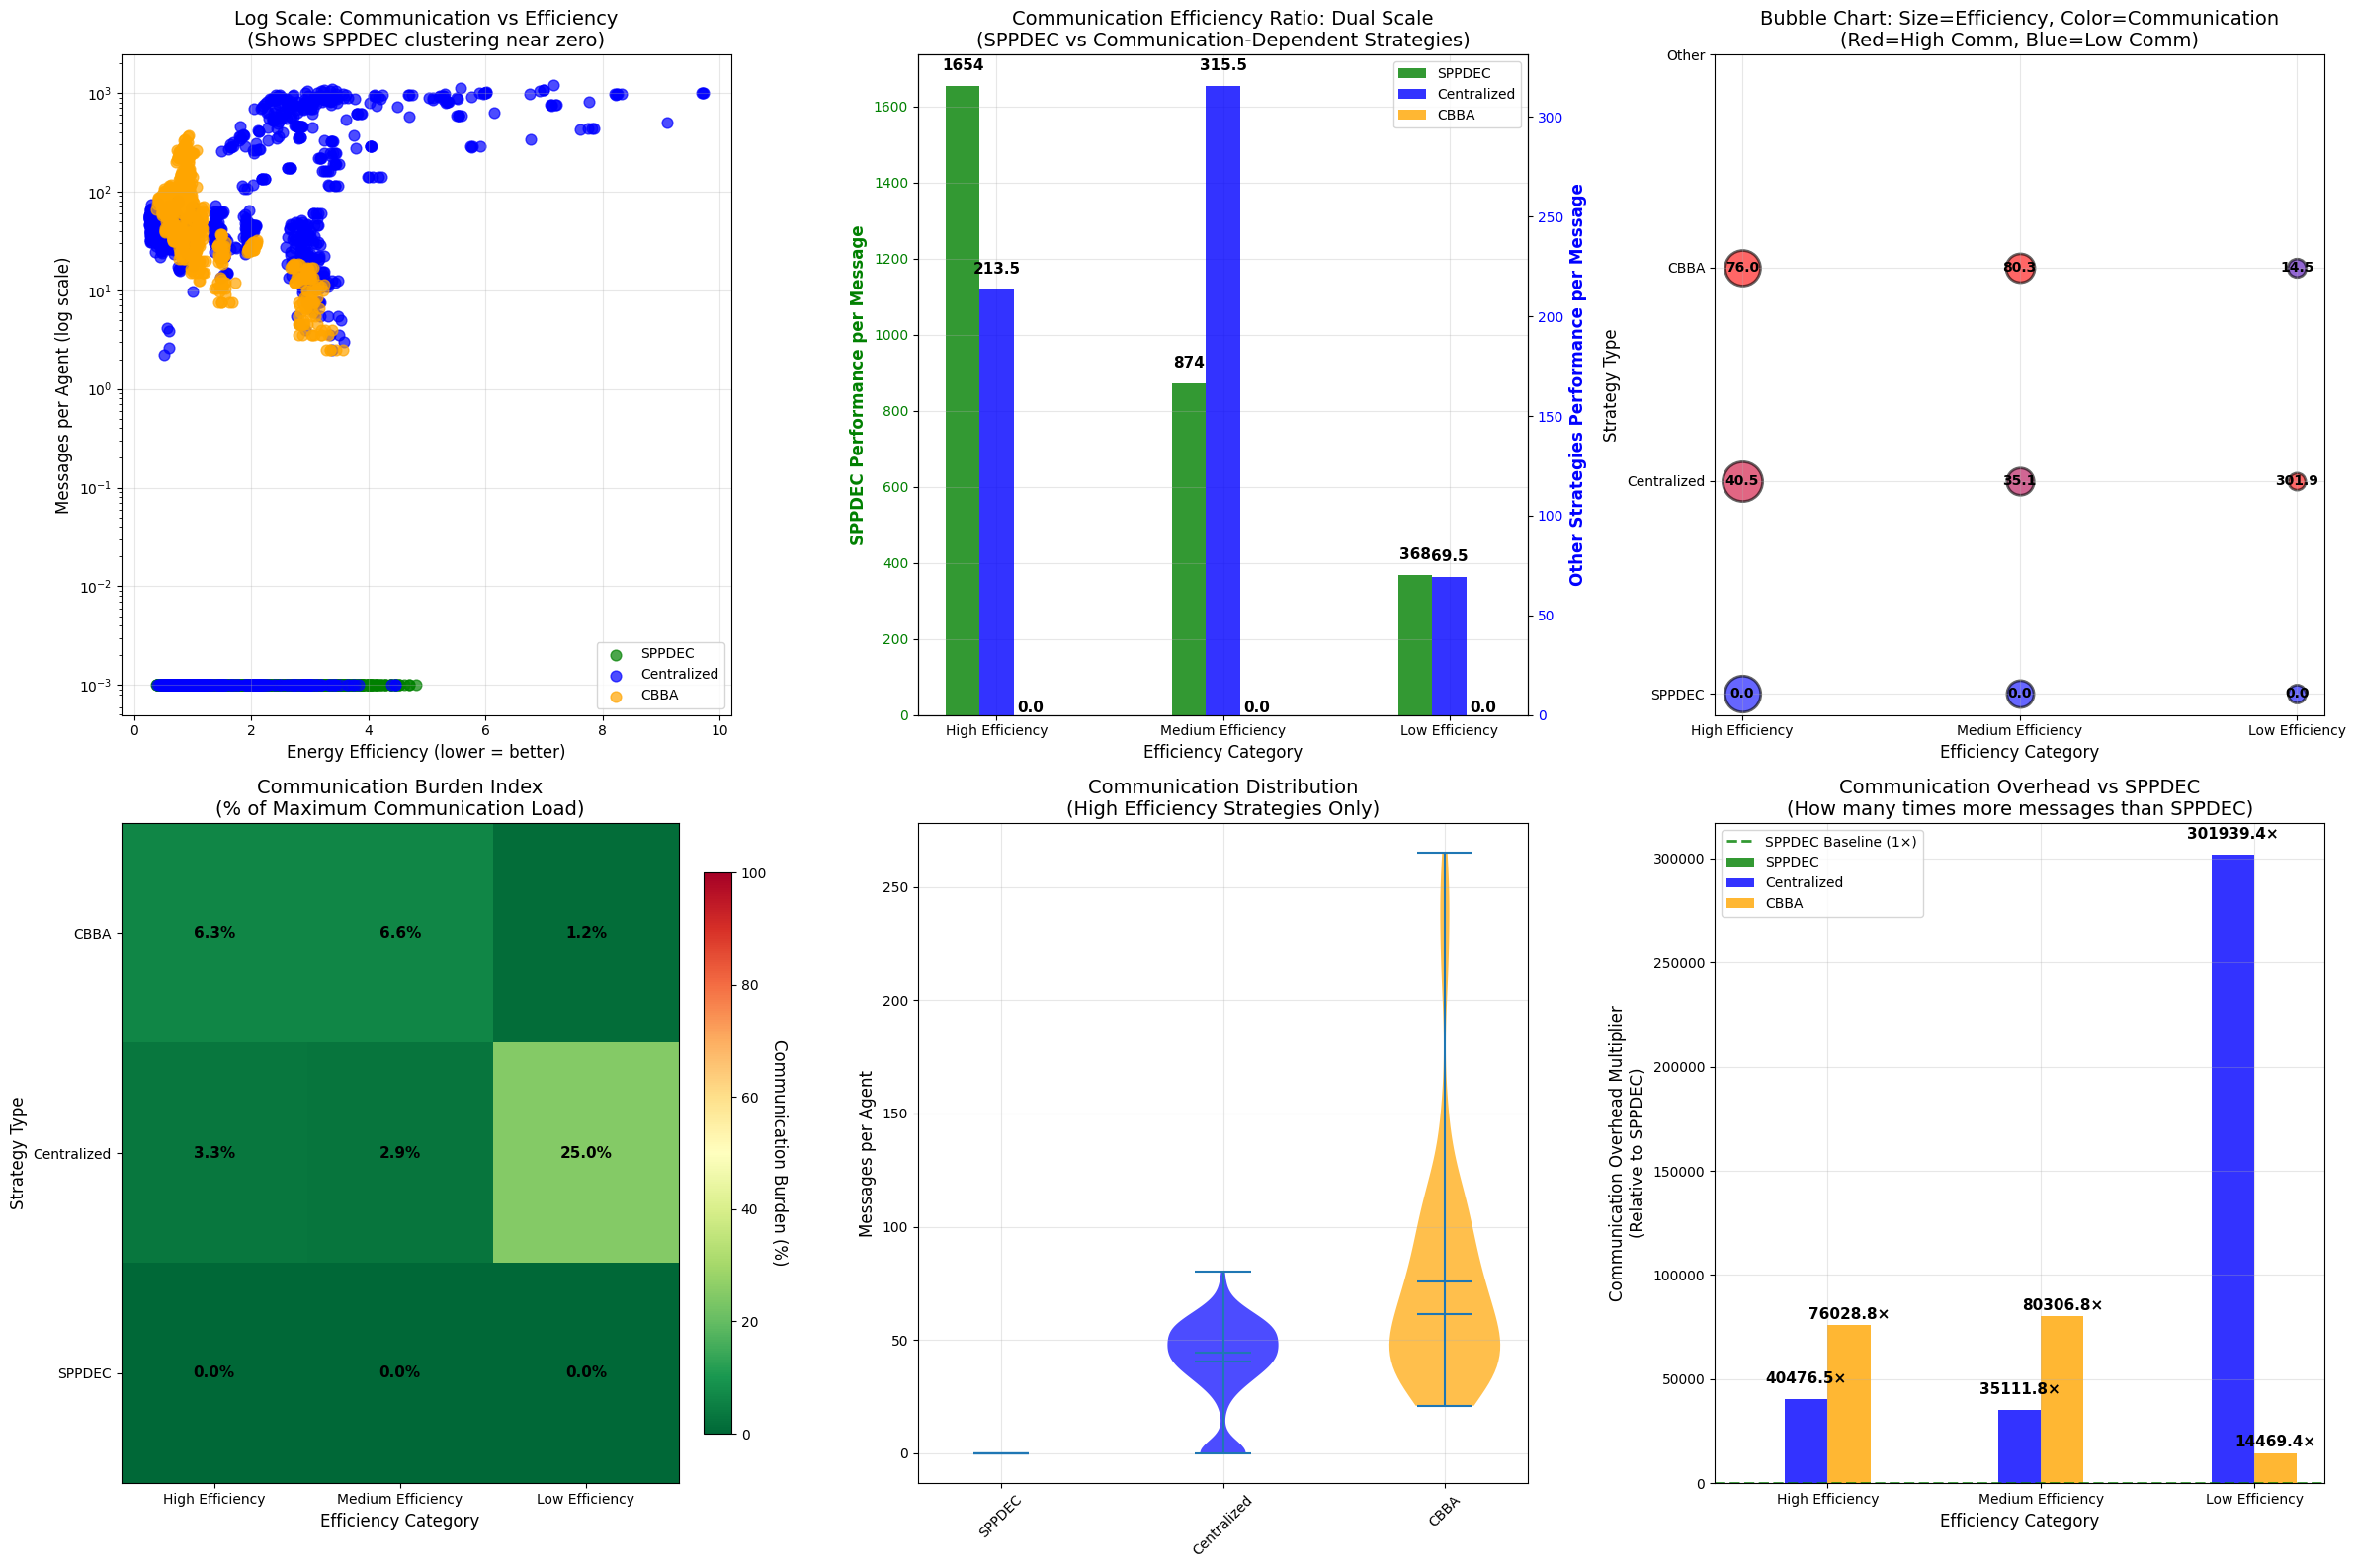


🎯 Alternative Visualization Insights:
1. Log Scale: Shows SPPDEC clustering near zero communication
2. Dual-Axis Efficiency Ratio: SPPDEC delivers orders-of-magnitude higher performance per message
3. Bubble Chart: Visualizes efficiency vs communication trade-offs
4. Burden Index: Shows SPPDEC's minimal communication burden
5. Violin Plots: Distribution of communication patterns
6. Overhead Multiplier: Quantifies how much more other strategies communicate


In [27]:
notebook_analyzer.plot_sppdec_communication_advantage()

## Custom Analysis

Direct access to the DataFrame for custom analysis:

In [28]:
# Raw DataFrame access (NO CHANGES)
df = notebook_analyzer.sweep.dataframe
print("DataFrame shape:", df.shape)
print("\nColumns:")
for col in sorted(df.columns):
    print(f"  {col}")

DataFrame shape: (5351, 33)

Columns:
  battery_capacity
  comm_reliability
  config_name
  distance_per_task
  efficiency_ratio
  energy_efficiency
  energy_per_agent
  energy_per_task
  failure_rate
  makespan_per_parcel
  messages_sent
  mission_makespan_steps
  n_agents
  n_collisions
  n_parcels
  parcels_delivered
  parcels_picked
  personality_distribution
  personality_map
  planner
  run_id
  runtime_seconds
  scale_factor
  seed
  strategy_family
  strategy_name
  sweep_name
  tasks_completed
  total_cell_visits
  total_distance_traveled
  total_energy_consumed
  unique_cells_explored
  unsafe_failures


In [29]:
# Performance calculations (NO CHANGES)
sppdec_df = notebook_analyzer.sweep.get_sppdec_phases()
if 'Combined' in sppdec_df['sppdec_phase'].values and 'Control' in sppdec_df['sppdec_phase'].values:
    combined_perf = sppdec_df[sppdec_df['sppdec_phase'] == 'Combined'].groupby('config_name')['mission_makespan_steps'].mean()
    control_perf = sppdec_df[sppdec_df['sppdec_phase'] == 'Control'].groupby('config_name')['mission_makespan_steps'].mean()
    
    improvement = ((control_perf - combined_perf) / control_perf * 100)
    
    print("SPPDEC Combined vs Control - Speed Improvement:")
    for config, imp in improvement.items():
        print(f"  {config}: {imp:.1f}% faster")
    
    print(f"\nAverage improvement: {improvement.mean():.1f}%")

SPPDEC Combined vs Control - Speed Improvement:
  A10_P12: 4.6% faster
  A10_P14: 19.0% faster
  A10_P20: -8.5% faster
  A10_P22: 11.6% faster
  A10_P24: -0.9% faster
  A10_P26: 11.4% faster
  A10_P30: 1.9% faster
  A10_P36: 6.5% faster
  A10_P4: -8.2% faster
  A10_P8: 11.3% faster
  A12_P12: -1.2% faster
  A12_P24: -8.8% faster
  A12_P26: 4.6% faster
  A12_P4: -1.0% faster
  A15_P12: -0.2% faster
  A15_P14: -0.1% faster
  A15_P20: -10.0% faster
  A15_P24: -40.5% faster
  A15_P26: 14.4% faster
  A15_P30: 5.8% faster
  A15_P36: -8.4% faster
  A15_P4: -1.6% faster
  A15_P8: 1.6% faster
  A18_P36: 3.5% faster
  A20_P12: -2.7% faster
  A20_P14: 5.1% faster
  A20_P20: 0.4% faster
  A20_P24: 2.0% faster
  A20_P26: 1.8% faster
  A20_P30: -21.1% faster
  A20_P36: -5.4% faster
  A20_P4: 5.9% faster
  A20_P8: 7.2% faster
  A2_P12: -8.8% faster
  A2_P14: -2.0% faster
  A2_P20: 4.2% faster
  A2_P24: -7.4% faster
  A2_P26: -3.2% faster
  A2_P30: -5.6% faster
  A2_P36: 4.9% faster
  A2_P4: 12.0% fas

## Export Results

Save all analysis to CSV files:

In [30]:
# Export results (NO CHANGES)
output_dir = Path("../results") / "sweep_analysis"
notebook_analyzer.export_results(output_dir)
print(f"Results saved to: {output_dir.absolute()}")

✅ Results exported to: ../results/sweep_analysis
Results saved to: /home/iamthevectorian/PycharmProjects/MultiAgentSimulator/analysis/notebooks/../results/sweep_analysis


In [31]:
slm.switching_rate(groupby=["config_name"]).query(
    "config_name in ['A3_P36','A6_P36','A12_P36','A18_P36']"
)

,config_name,n_decisions,n_switched,switch_rate
0,A12_P36,2560,935,0.3652
1,A18_P36,2658,1872,0.7043
2,A3_P36,2028,222,0.1095
3,A6_P36,2564,127,0.0495


In [32]:
slm.context_profile(groupby=["config_name", "policy"]).query(
    "config_name in ['A3_P36','A6_P36','A12_P36','A18_P36']"
)

,config_name,policy,belief_infeasibility,energy_error,competition_ratio,confidence
0,A12_P36,greedy,0.5568,1.3977,0.4716,0.6556
1,A12_P36,hungarian,0.6361,1.8780,1.2125,0.4304
2,A18_P36,greedy,0.5464,0.5691,0.6705,0.6249
3,A18_P36,hungarian,0.5307,2.0342,1.1486,0.4267
4,A3_P36,greedy,0.8289,1.3984,0.1381,0.8865
5,A3_P36,hungarian,0.9760,1.8179,0.7218,0.4854
6,A6_P36,greedy,0.7409,0.9221,0.3779,0.9121
7,A6_P36,hungarian,0.8980,1.9936,1.1742,0.4044


In [33]:
df = slm.switching_rate(groupby=["config_name","strategy_name"])
df["personality"] = df["strategy_name"].str.extract(
    r'sppdec_personality_mix_(\w+)_instance'
)
df.groupby(["config_name","personality"])["switch_rate"].mean()

config_name                        personality         
A12_P36                            3_brains_1_wildcard     0.38262
                                   balanced_quartet        0.33894
                                   controlled_chaos        0.39898
                                   efficiency_overdrive    0.37474
                                   no_reckless             0.37114
A18_P36                            3_brains_1_wildcard     0.70972
                                   balanced_quartet        0.67036
                                   controlled_chaos        0.68730
                                   efficiency_overdrive    0.69324
                                   no_reckless             0.70888
A3_P36                             3_brains_1_wildcard     0.13170
                                   balanced_quartet        0.09102
                                   controlled_chaos        0.10188
                                   efficiency_overdrive    0.09400
      

In [34]:
n_divergence = len(slm.divergence_events(threshold=0.01))
n_switched   = slm.switching_rate()["n_switched"].sum()
n_decisions  = slm.switching_rate()["n_decisions"].sum()
print(f"Divergence events:  {n_divergence}")
print(f"Hungarian selected: {n_switched} ({n_switched/n_decisions*100:.1f}% of all decisions)")
print(f"Of divergent cases: {n_switched/n_divergence*100:.1f}% resulted in Hungarian")

Divergence events:  6253
Hungarian selected: 3553 (24.3% of all decisions)
Of divergent cases: 56.8% resulted in Hungarian


In [35]:
a3_hungarian = slm.dataframe.query(
    "config_name == 'A3_P36' and policy == 'hungarian'"
)
print(a3_hungarian[["cost_delta","cost_greedy","cost_hungarian",
                     "belief_infeasibility","confidence"]].describe())

       cost_delta  cost_greedy  cost_hungarian  belief_infeasibility  \
count  222.000000   222.000000      222.000000            222.000000   
mean     0.057549     4.330511        4.388060              0.976010   
std      0.154102     1.839223        1.876017              0.055326   
min      0.000000     0.315714        0.315714              0.571429   
25%      0.000000     3.915690        3.917695              0.984849   
50%      0.000000     4.662823        4.669101              1.000000   
75%      0.000000     5.441457        5.486527              1.000000   
max      1.399155    10.263789       10.263789              1.000000   

       confidence  
count  222.000000  
mean     0.485379  
std      0.208025  
min      0.000000  
25%      0.250000  
50%      0.513538  
75%      0.625000  
max      0.716324  


In [36]:
slm.context_profile(groupby=["config_name", "policy"]).query(
    "config_name in ['A3_P36','A6_P36','A12_P36']"
)

,config_name,policy,belief_infeasibility,energy_error,competition_ratio,confidence
0,A12_P36,greedy,0.5568,1.3977,0.4716,0.6556
1,A12_P36,hungarian,0.6361,1.8780,1.2125,0.4304
4,A3_P36,greedy,0.8289,1.3984,0.1381,0.8865
5,A3_P36,hungarian,0.9760,1.8179,0.7218,0.4854
6,A6_P36,greedy,0.7409,0.9221,0.3779,0.9121
7,A6_P36,hungarian,0.8980,1.9936,1.1742,0.4044


In [37]:
df = slm.switching_rate(groupby=["config_name","strategy_name"])
df["personality"] = df["strategy_name"].str.extract(
    r'sppdec_personality_mix_(\w+)_instance'
)
df.groupby(["config_name","personality"])["switch_rate"].mean()

config_name                        personality         
A12_P36                            3_brains_1_wildcard     0.38262
                                   balanced_quartet        0.33894
                                   controlled_chaos        0.39898
                                   efficiency_overdrive    0.37474
                                   no_reckless             0.37114
A18_P36                            3_brains_1_wildcard     0.70972
                                   balanced_quartet        0.67036
                                   controlled_chaos        0.68730
                                   efficiency_overdrive    0.69324
                                   no_reckless             0.70888
A3_P36                             3_brains_1_wildcard     0.13170
                                   balanced_quartet        0.09102
                                   controlled_chaos        0.10188
                                   efficiency_overdrive    0.09400
      

In [38]:
n_divergence = len(slm.divergence_events(threshold=0.01))
n_switched   = slm.switching_rate()["n_switched"].sum()
n_decisions  = slm.switching_rate()["n_decisions"].sum()
print(f"Divergence events:  {n_divergence}")
print(f"Hungarian selected: {n_switched} ({n_switched/n_decisions*100:.1f}% of all decisions)")
print(f"Of divergent cases: {n_switched/n_divergence*100:.1f}% resulted in Hungarian")

Divergence events:  6253
Hungarian selected: 3553 (24.3% of all decisions)
Of divergent cases: 56.8% resulted in Hungarian


In [39]:
a3_hungarian = slm.dataframe.query(
    "config_name == 'A3_P36' and policy == 'hungarian'"
)
print(a3_hungarian[["cost_delta","cost_greedy","cost_hungarian",
                     "belief_infeasibility","confidence"]].describe())

       cost_delta  cost_greedy  cost_hungarian  belief_infeasibility  \
count  222.000000   222.000000      222.000000            222.000000   
mean     0.057549     4.330511        4.388060              0.976010   
std      0.154102     1.839223        1.876017              0.055326   
min      0.000000     0.315714        0.315714              0.571429   
25%      0.000000     3.915690        3.917695              0.984849   
50%      0.000000     4.662823        4.669101              1.000000   
75%      0.000000     5.441457        5.486527              1.000000   
max      1.399155    10.263789       10.263789              1.000000   

       confidence  
count  222.000000  
mean     0.485379  
std      0.208025  
min      0.000000  
25%      0.250000  
50%      0.513538  
75%      0.625000  
max      0.716324  


In [40]:
a3_hungarian = slm.dataframe.query(
    "config_name == 'A6_P36' and policy == 'hungarian'"
)
print(a3_hungarian[["cost_delta","cost_greedy","cost_hungarian",
                     "belief_infeasibility","confidence"]].describe())

       cost_delta  cost_greedy  cost_hungarian  belief_infeasibility  \
count  127.000000   127.000000      127.000000            127.000000   
mean     0.157667     3.728201        3.885869              0.898030   
std      0.475378     1.944508        2.057156              0.123145   
min      0.000000     0.312282        0.312282              0.500000   
25%      0.000000     1.959035        2.039908              0.823814   
50%      0.000000     3.996935        4.148145              0.937741   
75%      0.070061     5.179650        5.432856              1.000000   
max      3.118799     7.715435        8.295345              1.000000   

       confidence  
count  127.000000  
mean     0.404403  
std      0.288520  
min      0.000000  
25%      0.000000  
50%      0.500000  
75%      0.666667  
max      0.800000  


In [41]:
a3_hungarian = slm.dataframe.query(
    "config_name == 'A12_P36' and policy == 'hungarian'"
)
print(a3_hungarian[["cost_delta","cost_greedy","cost_hungarian",
                     "belief_infeasibility", "confidence"]].describe())

       cost_delta  cost_greedy  cost_hungarian  belief_infeasibility  \
count  935.000000   935.000000      935.000000            935.000000   
mean     0.325297     2.504865        2.830162              0.636121   
std      0.560695     1.153825        1.318351              0.216074   
min      0.000000     0.269775        0.269775              0.000000   
25%      0.000000     1.697787        1.888588              0.500000   
50%      0.000000     2.622370        2.916185              0.500000   
75%      0.425882     3.252744        3.742278              0.861665   
max      3.447263     6.183959        6.289100              1.000000   

       confidence  
count  935.000000  
mean     0.430355  
std      0.228312  
min      0.000000  
25%      0.316296  
50%      0.454545  
75%      0.625000  
max      0.840000  


In [42]:
a3_hungarian = slm.dataframe.query(
    "config_name == 'A18_P36' and policy == 'hungarian'"
)
print(a3_hungarian[["cost_delta","cost_greedy","cost_hungarian",
                     "belief_infeasibility", "confidence"]].describe())

        cost_delta  cost_greedy  cost_hungarian  belief_infeasibility  \
count  1872.000000  1872.000000     1872.000000           1872.000000   
mean      0.488390     1.461630        1.950021              0.530715   
std       0.697760     0.909915        1.046254              0.114011   
min       0.000000     0.254127        0.254127              0.500000   
25%       0.000000     0.688016        1.206754              0.500000   
50%       0.087262     1.423112        1.910736              0.500000   
75%       0.826469     2.066752        2.581166              0.500000   
max       3.709962     5.335673        5.609808              1.000000   

        confidence  
count  1872.000000  
mean      0.426681  
std       0.216108  
min       0.000000  
25%       0.328125  
50%       0.456522  
75%       0.590909  
max       0.800000  


In [48]:
from analysis.hybrid_metrics import HybridMetricsAnalyzer

analyzer = HybridMetricsAnalyzer.from_strategy_dir(
    "/home/iamthevectorian/PycharmProjects/MultiAgentSimulator/experiments/station_scaling/A3_P36/experiment_73ad2ffb/sppdec_combined_instance_1"
)
analyzer.generate_tier1_report("figures/phase10/")

  Loaded: HybridRecord(config='', strategy='sppdec_combined_instance_1', R=inf, ticks=752, corrections=0)
Generating Tier 1 report for: sppdec_combined_instance_1
Saved: figures/phase10/fig_p10_error_vs_visibility.pdf
  Skipped error_vs_time: No hidden-peer observations found. Ensure visibility_radius < inf so some peers are ever invisible.
  Skipped confidence_decay: No hidden-peer observations found.
Tier 1 report written to: figures/phase10
